# Smoothing

**A moving average makes a noisy pattern easier to see, but one that uses later rows quietly hands your model the future.**

This chapter builds two trailing averages: `simple_moving_average`, the plain mean of the last few rows, and `exponential_moving_average`, which gives recent rows more weight. Both are causal: the smoothed value at a row uses that row and the rows before it, never the ones after. Both helpers are deprecated and leave the package in TimeGym 2.0; this chapter keeps them as worked examples.

We smooth a noisy cycle that we generated ourselves, so the true cycle under the noise is known. That lets us measure what a longer window buys and what it costs, see why a centered average that looks better is a leak, and match the exponential weight to a window length.

**Development notebook.** The collapsed cells are the library code; expand one to edit it, then follow the [build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp smoothing

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})

import warnings

# Both smoothing helpers are deprecated and leave the package in TimeGym 2.0. This chapter keeps them as worked
# examples, so their deprecation warnings are silenced here.
warnings.filterwarnings('ignore', message=r'.* is deprecated and will be removed in TimeGym 2\.0',
                        category=DeprecationWarning)

## Two trailing averages

Both helpers smooth every column of a Series or DataFrame on its own and return the same type, with the same index and labels, holding only the smoothed values. The input is never changed.

In [3]:
#| export smoothing
from __future__ import annotations

from numbers import Real
from typing import TypeVar
import math

import pandas as pd
from timegym._internal import positive_int, nonnegative_int, _deprecated

_Pandas = TypeVar("_Pandas", pd.Series, pd.DataFrame)
_RECIPE = ('the package has no replacement; the recipe stays in the source notebook chapter '
           '"Smoothing" (source/03_smoothing.ipynb)')


### The mean of the last few rows: `simple_moving_average`

`window_length` counts rows, including the current one. `min_periods` (default 1) is how many non-missing values a window needs before it returns a number: missing values are skipped, and a window with fewer gives NaN. With the default, the first rows average over whatever history exists.

In [4]:
#| export smoothing
def simple_moving_average(
    df: _Pandas, window_length: int = 30, min_periods: int = 1
) -> _Pandas:
    """Average each column over a trailing window, including the current row.

    Return the input's pandas type, index and labels with only smoothed values;
    do not mutate the input or append columns. window_length counts rows and
    min_periods counts nonmissing observations per column (0..window_length).
    Missing values are skipped; insufficient observations yield NaN. Shift the
    result by one row if used as a feature predicting the current observation.
    """
    _deprecated("simple_moving_average", _RECIPE)
    if not isinstance(df, (pd.Series, pd.DataFrame)):
        raise TypeError("df must be a pandas Series or DataFrame")
    window_length = positive_int(window_length, "window_length")
    min_periods = nonnegative_int(min_periods, "min_periods")
    if min_periods > window_length:
        raise ValueError("min_periods must not exceed window_length")
    return df.rolling(window_length, min_periods=min_periods).mean()


### Recent rows count more: `exponential_moving_average`

A row `k` steps old gets weight `(1 - alpha)**k`, and the weights are rescaled to sum to one over the rows available. A large `exponential_alpha` (at most 1) follows the latest values closely; a small one remembers longer. A missing row still counts as a step, so the values before it keep aging. `min_periods` means the same as above, and only the mean is supported.

In [5]:
#| export smoothing
def exponential_moving_average(
    df: _Pandas,
    exponential_alpha: float | None = None,
    statistic: str = "mean",
    *,
    min_periods: int = 1,
) -> _Pandas:
    """Average each column with normalized, trailing exponential weights.

    Return the input's pandas type, index and labels without mutation. An
    observation k rows old has weight (1-alpha)**k, normalized over available
    observations (adjust=True, ignore_na=False). min_periods counts nonmissing
    observations per column; insufficient history yields NaN. The current row
    is included, so shift before using this as a contemporaneous predictor.
    Only statistic='mean' is supported.
    """
    _deprecated("exponential_moving_average", _RECIPE)
    if not isinstance(df, (pd.Series, pd.DataFrame)):
        raise TypeError("df must be a pandas Series or DataFrame")
    if statistic != "mean":
        raise ValueError(
            "Only statistic='mean' is supported; pandas EWM does not provide a median"
        )
    if (
        isinstance(exponential_alpha, bool)
        or not isinstance(exponential_alpha, Real)
        or not math.isfinite(exponential_alpha)
        or not 0 < exponential_alpha <= 1
    ):
        raise ValueError("Supply exponential_alpha in (0, 1]")
    min_periods = nonnegative_int(min_periods, "min_periods")
    return df.ewm(
        alpha=float(exponential_alpha),
        min_periods=min_periods,
        adjust=True,
        ignore_na=False,
    ).mean()


## How long a window?

The series is noise around a repeating cycle: a sine wave that swings 3 above and below zero and repeats every 36 steps, plus noise with a standard deviation of 1. Because we generated it, we know the cycle under the noise exactly, and can measure how far each smoothed curve sits from it. A trailing window of `w` rows is centered `(w - 1) / 2` steps in the past, so that is how far it trails a changing signal. We try windows of 3, 12 and 30 rows.

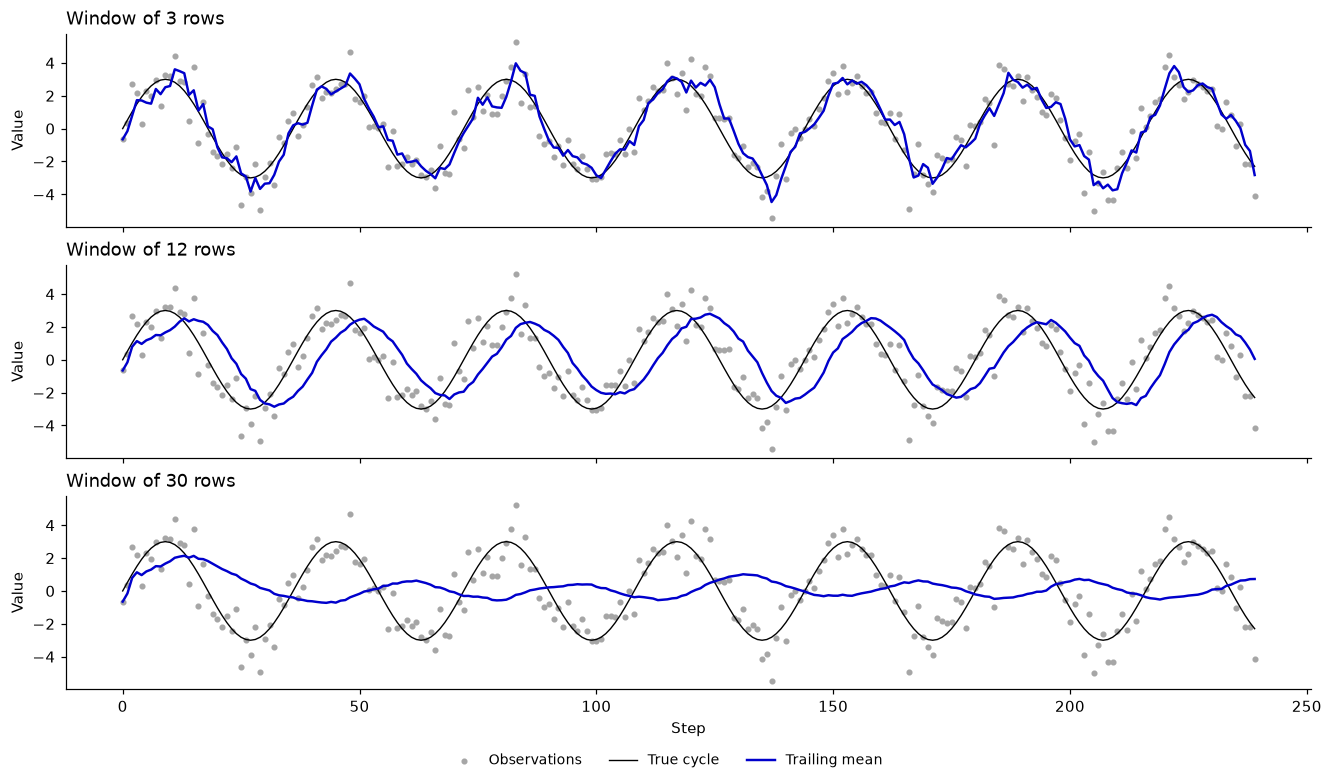

,Trails by (steps),Average distance from the true cycle
Raw observations,0.0,0.78
Window of 3,1.0,0.53
Window of 12,5.5,1.62
Window of 30,14.5,2.18


In [6]:
from timegym import Scenario

amplitude, period, sigma = 3.0, 36.0, 1.0
case = Scenario('seasonal', context_length=240, horizon=24,
                parameters={'amplitude': amplitude, 'period': period, 'sigma': sigma}).generate(seed=4)
context = case.task.context


def true_cycle(steps):
    return amplitude * np.sin(2 * np.pi * np.asarray(steps, dtype=float) / period)


np.testing.assert_allclose(case.reference.mean[:, 0], true_cycle(case.task.future_index))  # the answer key continues this cycle
cycle = pd.Series(true_cycle(context.index), index=context.index)


def distance(smoothed):
    # Average distance from the true cycle, from row 30 on, where every window is full.
    return (smoothed['y'] - cycle).abs().iloc[30:].mean()


windows = (3, 12, 30)
smoothed = {w: simple_moving_average(context, window_length=w) for w in windows}
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True, layout='constrained')
for ax, w in zip(axes, windows):
    ax.scatter(context.index, context['y'], s=9, color='0.65', label='Observations')
    ax.plot(cycle.index, cycle, color='black', lw=0.9, label='True cycle')
    ax.plot(smoothed[w].index, smoothed[w]['y'], color='#0000CC', lw=1.6, label='Trailing mean')
    ax.set(title=f'Window of {w} rows', ylabel='Value')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=3, fontsize=9)
axes[-1].set_xlabel('Step')
plt.show()

table = pd.DataFrame({'Trails by (steps)': [0, *[(w - 1) / 2 for w in windows]],
                      'Average distance from the true cycle': [distance(context), *[distance(smoothed[w]) for w in windows]]},
                     index=['Raw observations', *[f'Window of {w}' for w in windows]])
assert table.iloc[1, 1] < table.iloc[0, 1]  # a short window gets closer to the cycle than the raw data
assert table.iloc[2, 1] > table.iloc[0, 1]  # a window of 12 is smoother, yet further away
table.round(2)

The window of 3 removes some noise and stays close to the cycle: on average it sits 0.53 from the truth, against 0.78 for the raw observations. The window of 12 looks far smoother, yet sits further from the cycle than the raw data (1.62): it trails by five and a half steps and shaves off the peaks. At 30 rows, close to a whole cycle, the curve is almost flat. Smoothing trades noise for delay, so pick a window that is short compared with how fast the signal moves.

## Smooth without reading the future

A centered average, the kind a charting tool draws, puts its window around each row instead of behind it, so it doesn't trail. It also reads ahead. The test that tells the two kinds apart: smooth the first 100 rows, then all 240, and count how many of the first 100 values changed. A causal average can't change when later rows arrive.

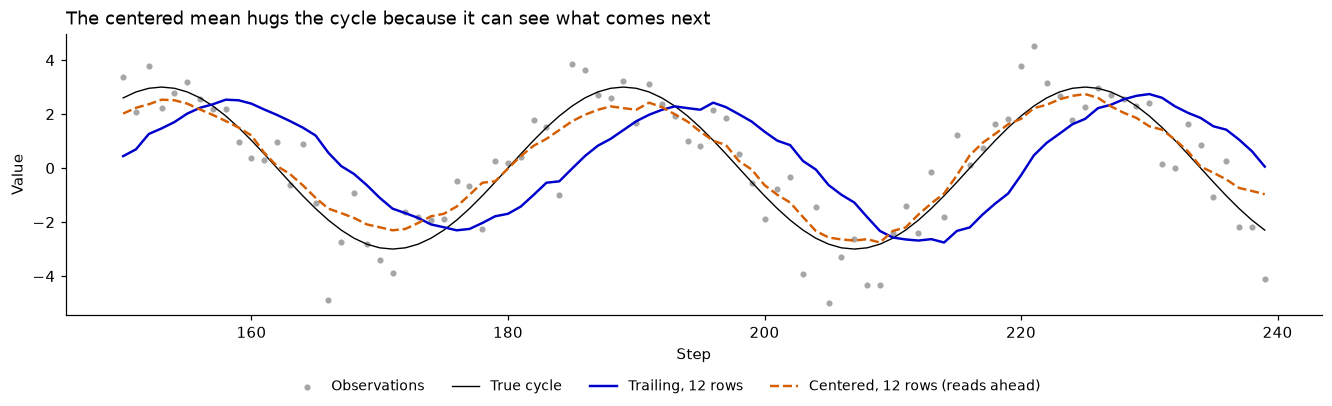

,Average distance from the true cycle,Values that changed when 140 rows arrived
"Trailing, 12 rows",1.62,0
"Centered, 12 rows",0.43,5


In [7]:
def centered(frame):
    # A 12-row window around each row, built with pandas for comparison.
    return frame.rolling(12, center=True, min_periods=1).mean()


first_100 = context.iloc[:100]
leak_test = pd.DataFrame({
    'Average distance from the true cycle': [distance(smoothed[12]), distance(centered(context))],
    'Values that changed when 140 rows arrived': [
        int((~np.isclose(simple_moving_average(first_100, window_length=12)['y'], smoothed[12]['y'].iloc[:100])).sum()),
        int((~np.isclose(centered(first_100)['y'], centered(context)['y'].iloc[:100])).sum())]},
    index=['Trailing, 12 rows', 'Centered, 12 rows'])
assert leak_test.iloc[0, 1] == 0  # the trailing mean never reads ahead
assert leak_test.iloc[1, 1] > 0  # the centered one does

recent = slice(150, None)
fig, ax = plt.subplots(figsize=(12, 3.6), layout='constrained')
ax.scatter(context.index[recent], context['y'].iloc[recent], s=9, color='0.65', label='Observations')
ax.plot(cycle.index[recent], cycle.iloc[recent], color='black', lw=0.9, label='True cycle')
ax.plot(context.index[recent], smoothed[12]['y'].iloc[recent], color='#0000CC', lw=1.6, label='Trailing, 12 rows')
ax.plot(context.index[recent], centered(context)['y'].iloc[recent], color='#D55E00', lw=1.6, ls='--',
        label='Centered, 12 rows (reads ahead)')
ax.set(title='The centered mean hugs the cycle because it can see what comes next', xlabel='Step', ylabel='Value')
fig.legend(loc='outside lower center', ncol=4, fontsize=9)
plt.show()
leak_test.round(2)

The centered average sits 0.43 from the true cycle, against 1.62 for the trailing one, and it is the one you can't use: five of its first 100 values changed when the later rows arrived, because they had been computed from rows that came after them. As a model input those values would carry information from after the forecast date. The trailing average didn't change at all. That is what causal means here, and the delay is its price.

### To predict a row, shift by one

A trailing average includes the current row. That is right for a chart, but a model predicting row `t` may use only the rows before it, so shift the average down one row before using it as an input. Passing a Series returns a Series:

In [8]:
recent_mean = simple_moving_average(context['y'], window_length=3)
inputs = pd.DataFrame({'y': context['y'], 'mean of the last 3 rows': recent_mean,
                       'usable to predict y': recent_mean.shift(1)})
assert np.isclose(inputs.loc[10, 'usable to predict y'], context['y'].iloc[7:10].mean())  # rows 7 to 9 only
inputs.head(5).round(2)

,y,mean of the last 3 rows,usable to predict y
0,-0.65,-0.65,NaN
1,0.35,-0.15,-0.65
2,2.69,0.79,-0.15
3,2.16,1.73,0.79
4,0.29,1.71,1.73


Row 0 has nothing to predict from, so its input is missing. Rows 1 and 2 average the one and two rows before them, because the default `min_periods=1` accepts a short window.

## Exponential weights: alpha instead of a window

`exponential_alpha` plays the part of the window length. A common rule of thumb matches the two by the average age of the values they use: alpha = 2 / (window + 1). So alpha 0.5 should behave like a window of 3, and alpha 0.1 like a window of 19.

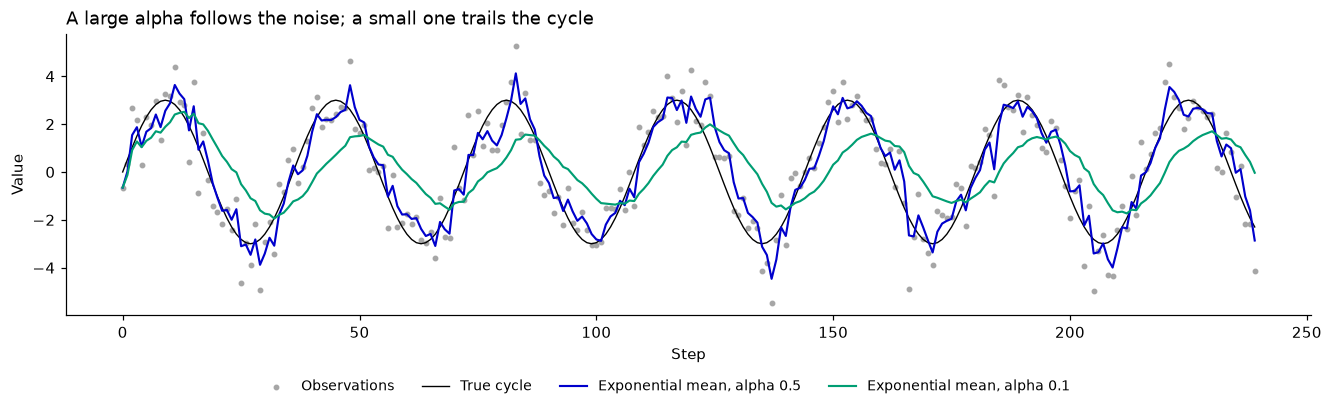

,Average distance from the true cycle
"Exponential, alpha 0.5",0.53
"Trailing, window of 3",0.53
"Exponential, alpha 0.1",1.53
"Trailing, window of 19",2.19


In [9]:
alphas = {0.5: 3, 0.1: 19}
exponential = {alpha: exponential_moving_average(context, exponential_alpha=alpha) for alpha in alphas}
fig, ax = plt.subplots(figsize=(12, 3.6), layout='constrained')
ax.scatter(context.index, context['y'], s=8, color='0.65', label='Observations')
ax.plot(cycle.index, cycle, color='black', lw=0.9, label='True cycle')
for (alpha, curve), color in zip(exponential.items(), ['#0000CC', '#009E73']):
    ax.plot(curve.index, curve['y'], color=color, lw=1.4, label=f'Exponential mean, alpha {alpha}')
ax.set(title='A large alpha follows the noise; a small one trails the cycle', xlabel='Step', ylabel='Value')
fig.legend(loc='outside lower center', ncol=4, fontsize=9)
plt.show()

matched = pd.Series({label: distance(curve) for alpha, w in alphas.items() for label, curve in [
    (f'Exponential, alpha {alpha}', exponential[alpha]),
    (f'Trailing, window of {w}', simple_moving_average(context, window_length=w))]},
    name='Average distance from the true cycle')
matched.round(2).to_frame()

Alpha 0.5 lands where the window of 3 did, 0.53 from the true cycle in both cases, and like it follows much of the noise. Alpha 0.1 smooths about as hard as a window of 19 but stays closer to this cycle (1.53 against 2.19): its newest rows still carry the most weight, while a flat window of 19 weighs a row 18 steps old as much as the current one.

## Change one thing

- Make the cycle twice as fast, `period = 18.0`: is a window of 3 still short enough?
- Raise the noise to `sigma = 3.0`. Now the window of 12 beats the raw observations, and the assert that says otherwise fails. Which window is closest to the cycle?
- Set `min_periods=12` with a window of 12: the first 11 values become NaN instead of averages over fewer rows.

**What this doesn't cover.** Only means: no medians, Kalman filters or Gaussian-process smoothers (the [archived smoothing notebook](https://github.com/diogoseca/timegym/blob/v1.4.0/source/archive/2.%20Smoothing.ipynb) sketched the last two). Windows count rows, not time, so on irregular timestamps a window of 12 rows can span very different durations.

**Next:** [04 · Feature engineering](04_feature_engineering.ipynb).